# AY_MA — NVDA Price & Moving Averages (Latest 180 Days)

This notebook connects to BigQuery, fetches the latest 180 days of price and SMA data for **NVDA** from the `fact_dailyprice` table, and visualizes:
1. **Price** (close)
2. **SMA 20**
3. **SMA 50**
4. **SMA 100**

---


In [1]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine

# 1. Force reload the updated .env file (wiping old memory cache)
load_dotenv(override=True)

# 2. Fetch your BigQuery project credentials
BILLING_PROJECT = os.getenv("BILLING_PROJECT_ID")
DATASET = os.getenv("DATASET_ID")

print(f"Billing Project: {BILLING_PROJECT}")
print(f"Dataset: {DATASET}")

# 3. Construct the official BigQuery dialect connection string
# Format: bigquery://billing-project-id/dataset-id
DATABASE_URL = f"bigquery://{BILLING_PROJECT}/{DATASET}"

# 4. Initialize the BigQuery SQLAlchemy engine
engine = create_engine(DATABASE_URL)

print("✅ Engine created successfully")

Billing Project: dsaimodule2-509312
Dataset: proj2sp500
✅ Engine created successfully


In [2]:
import pandas as pd

# Query: Select required columns for NVDA, latest 180 days
query = f"""
    SELECT
        date,
        ticker,
        close AS price,
        sma_20,
        sma_50,
        sma_100,
        sma_200
    FROM `{BILLING_PROJECT}.{DATASET}.fact_dailyprice`
    WHERE ticker = 'NVDA'
      AND date >= DATE_SUB((SELECT MAX(date) FROM `{BILLING_PROJECT}.{DATASET}.fact_dailyprice`), INTERVAL 180 DAY)
    ORDER BY date ASC
"""

print("Executing query...")
df = pd.read_sql(query, con=engine)

# Ensure date is datetime
df['date'] = pd.to_datetime(df['date'])

print(f"✅ Fetched {len(df)} rows")
print(f"Date range: {df['date'].min().date()} → {df['date'].max().date()}")
print(f"Columns: {list(df.columns)}")

Executing query...
✅ Fetched 125 rows
Date range: 2026-04-13 → 2026-10-08
Columns: ['date', 'ticker', 'price', 'sma_20', 'sma_50', 'sma_100', 'sma_200']


In [3]:
# Data verification
print("=== DataFrame Info ===")
print(df.info())

print("\n=== First 5 rows ===")
print(df.head())

print("\n=== Last 5 rows ===")
print(df.tail())

print("\n=== Descriptive Statistics ===")
print(df[['price', 'sma_20', 'sma_50', 'sma_100', 'sma_200']].describe())

=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     125 non-null    datetime64[ns]
 1   ticker   125 non-null    object        
 2   price    125 non-null    float64       
 3   sma_20   125 non-null    float64       
 4   sma_50   125 non-null    float64       
 5   sma_100  125 non-null    float64       
 6   sma_200  125 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 7.0+ KB
None

=== First 5 rows ===
        date ticker   price    sma_20    sma_50   sma_100    sma_200
0 2026-04-13   NVDA  189.31  177.8735  182.0138  182.8702  180.91690
1 2026-04-14   NVDA  196.51  178.5380  182.1214  182.9693  181.12435
2 2026-04-15   NVDA  198.87  179.3850  182.3866  183.1444  181.32995
3 2026-04-16   NVDA  198.35  180.2825  182.7468  183.2627  181.53175
4 2026-04-17   NVDA  201.

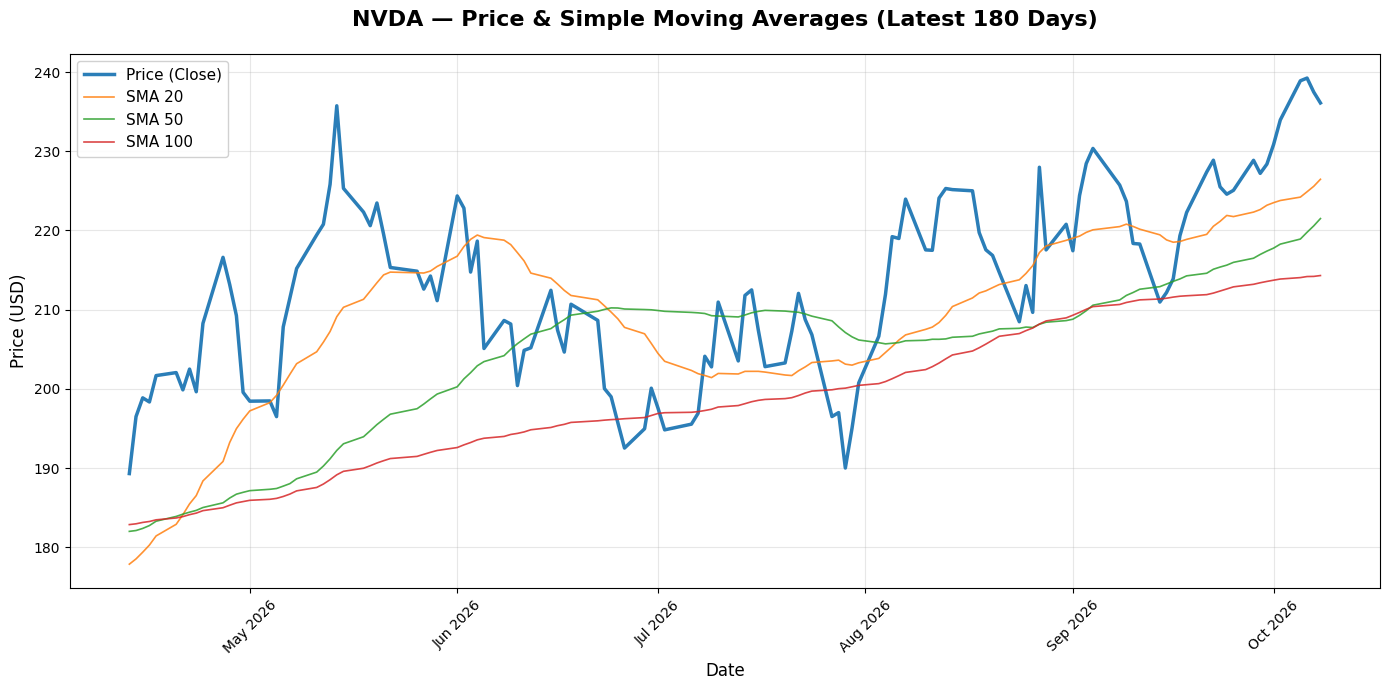

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Set up the figure
plt.figure(figsize=(14, 7))

# Plot the 4 lines
plt.plot(df['date'], df['price'], label='Price (Close)', linewidth=2.5, color='#1f77b4', alpha=0.95)
plt.plot(df['date'], df['sma_20'], label='SMA 20', linewidth=1.2, color='#ff7f0e', alpha=0.85)
plt.plot(df['date'], df['sma_50'], label='SMA 50', linewidth=1.2, color='#2ca02c', alpha=0.85)
plt.plot(df['date'], df['sma_100'], label='SMA 100', linewidth=1.2, color='#d62728', alpha=0.85)

# Add vertical dotted line for Q2 Earnings (Aug 26)
import datetime
earnings_date = pd.Timestamp('2025-08-26')
if df['date'].min() <= earnings_date <= df['date'].max():
    plt.axvline(x=earnings_date, color='lightblue', linestyle=':', linewidth=2, alpha=0.8, label='Q2 Earnings (Aug 26)')

# Formatting
plt.title('NVDA — Price & Simple Moving Averages (Latest 180 Days)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=11, framealpha=0.9)
plt.grid(True, alpha=0.3)

# Date formatting on x-axis
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

# Tight layout
plt.tight_layout()

# Show plot
plt.show()

---
## Interpretation

- **Price (blue)**: Actual daily closing price of NVDA
- **SMA 20 (orange)**: Short-term trend (≈1 trading month)
- **SMA 50 (green)**: Medium-term trend (≈2.5 trading months)
- **SMA 100 (red)**: Longer-term trend (≈5 trading months)

**Key signals to watch:**
- Price crossing above/below SMAs → potential trend changes
- SMA 20 crossing SMA 50 ("Golden Cross" / "Death Cross")
- All SMAs in bullish alignment (Price > SMA20 > SMA50 > SMA100) → strong uptrend
- All SMAs in bearish alignment → strong downtrend

---
*Data source: `fact_dailyprice` table in BigQuery project `dsaimodule2-509312`, dataset `proj2sp500`*